The goal of this notebook is to create annotations for the NN cell types.

The idea is to use annotations similar to the ABC atlas subclass for L2 such that clusters are recognizable. 

Starting L3, we append numbers.


In [1]:
from pathlib import Path
from dotenv import dotenv_values
from typing import Literal

import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt

In [ ]:
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

ADATA_IN_FP = DATADIR / "6_NC_projection" / 'all_integrated' / 'HypoMap3D_full.h5ad'

OUTDIR = DATADIR / "8_annotation"
OUTDIR.mkdir(exist_ok=True, parents=True)

### Let's load the NN cells

In [3]:
adata = sc.read_h5ad(ADATA_IN_FP, backed="r")
adata = adata[(adata.obs.L1.str.contains("NN")) & (adata.obs.IsControl)].to_memory()

In [4]:
print("normalizing")
sc.pp.normalize_total(adata, target_sum = 10_000) 
sc.pp.log1p(adata, base=2)

normalizing


In [5]:
adata

AnnData object with n_obs × n_vars = 290957 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'L1', 'L2', 'L3', 'L4', 'L5', 'C66_named_propagated', 'C185_named_propagated', 'C286_named_propagated', 'C465_named_propagated', 'class_id_label_propagated', 'subclass_id_label_propagated', 'supertype_id_label_propagated', 'cluster_id_label_propagated', 'XistExpressing', 'UtyExpressing', 'sex_per_sample_inferred', 'xist_pct_per_sample', 'uty_pct_per_sample', 'L1_descr_v0.6', 'L2_descr_v0.6', 'L3_descr_v0.6', 'L4_descr_v0.6', 'L5_descr_v0.6', 'L2_prelim', 'L3_prelim', 'L4_prelim', 'L5_prelim'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTF

## Functions for automatic annotation of subsequent levels based on previous

Algorithmically, we propagate the annotation of the parent level to the target level, then add a numerical suffix as well as the original cluster ID from the target level.

This propagation behavior is interrupted by passing a dictionary that maps ID -> annotation for specific clusters. This will insert specific hardcoded annotations for a given ID, after which this annotation will be propagated into the next level. 

Please note that we do not further split NN cells at L5. Hence, L5 is not plotted here.

In [ ]:

def annotate_level_NN(
    adata: ad.AnnData,
    source_col: str,
    parent_col: str,
    suffix_separator: Literal["_", "-"],
    manual_annot: dict | None
) -> None:
    """
    Annotate a new level in adata.obs based on source_col and optional manual annotations.
    Unmapped values will be renamed based on their parent_col with local enumeration.

    Parameters:
    - adata: AnnData object
    - source_col: name of source column in adata.obs
    - parent_col: name of the parent cluster column (used for naming)
    - suffix_separator: separator to use between parent label and cluster number
    - manual_annot: optional dictionary to map source_col values to annotations
    """

    target_col = source_col + "_new"

    # Step 1: Copy source_col to target_col
    adata.obs[target_col] = adata.obs[source_col].astype(str)

    # Step 2: Apply manual mapping if provided
    if manual_annot is not None:
        adata.obs[target_col] = adata.obs[target_col].map(manual_annot).fillna(adata.obs[source_col])

    # Step 3: Identify rows where target_col was not changed
    unchanged_mask = adata.obs[target_col] == adata.obs[source_col]

    # Step 4: For unchanged values, assign parent_col + local suffix
    if unchanged_mask.any():
        # Subset of rows that need relabeling
        df_subset = adata.obs.loc[unchanged_mask, [parent_col, source_col]].copy()

        # Group by parent and assign local suffixes to each unique source_col
        relabeled = []

        for parent, group in df_subset.groupby(parent_col):
            unique_sources = group[source_col].unique()
            local_map = {
                src: f"{parent}{suffix_separator}{i+1}" for i, src in enumerate(sorted(unique_sources))
            }
            relabeled.append(group[source_col].map(local_map))

        # Concatenate and assign back
        adata.obs.loc[unchanged_mask, target_col] = pd.concat(relabeled)

In [7]:
def annotate_NN_class_adata(
    adata: ad.AnnData,
    manual_annot: dict,
) -> None:
    """
    Annotate hierarchical clustering levels in an AnnData object using a mix of manual annotation
    and automatic propagation.

    This function builds standardized hierarchical labels across clustering levels L2 to L5:
    - Levels L2 to L4 are annotated using the `annotate_level_NN` function,
      which applies manual mappings where provided and generates consistent child labels.
    - L5 is always copied from L4.
    - Initial cluster IDs are always prepended at the end.

    Parameters:
    ----------
    adata : ad.AnnData
        The annotated data object containing `.obs` with clustering columns (L1–L5).
    
    manual_annot : dict
        A mapping from cluster labels to manually curated annotations. Applied at each level where available.

    """

    # Annotate L2 to L4
    for lvl in range(2, 5):
        suffix_separator = "_" if lvl < 4 else "-"
        source_col = f"L{lvl}"

        annotate_level_NN(
            adata=adata,
            source_col=source_col,
            parent_col=f"L{lvl-1}_new" if lvl > 2 else "L1",
            suffix_separator=suffix_separator,
            manual_annot=manual_annot
        )

    # Copy level 4 into level 5
    adata.obs["L5_new"] = adata.obs.L4_new.copy()

    # Prepend IDs
    for lvl in range(2, 6):
        adata.obs[f"L{lvl}_new"] = (
            adata.obs[f"L{lvl}"].astype(str)
            + " "
            + adata.obs[f"L{lvl}_new"].astype(str)
        )


## Let's annotate the Astro-Epen class  

For the Astro-Epen class, we annotate L2 according similar to ABC into Astrocytes/Tanycytes/Ependymal.

For L3, Tanycytes receive their widely used alpha/beta classification.

In [8]:
ae_adata = adata[adata.obs.L1.str.contains("Astro")].copy()

In [9]:
#sc.pl.umap(ae_adata, color=["L2", "L3", "L4",], ncols=2, frameon=False)

### Tanys

In [10]:
tany_adata = ae_adata[ae_adata.obs.L2 == "NN2-13"]

Our cell type split matches marker genes for the alpha/beta tanycytes as derived from [Tany-Seq paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC9104898/)

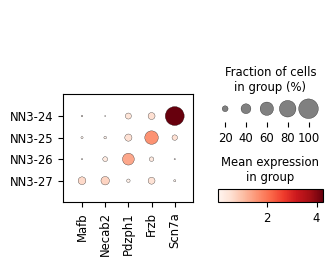

In [11]:
sc.pl.dotplot(tany_adata, var_names = ["Mafb", "Necab2", # alpha 1
                                    "Pdzph1", # alpha 2
                                    "Frzb", # beta 1
                                    "Scn7a", # beta 2
                                    ], groupby="L3")

### Let's annotate

In [12]:
ae_manual = {
    # L2
    "NN2-12": "Astro",
    "NN2-13": "Tanycyte",
    "NN2-14": "Ependymal",

    # L3
    "NN3-24": "Tanycyte_beta2",
    "NN3-25": "Tanycyte_beta1",
    "NN3-26": "Tanycyte_alpha2",
    "NN3-27": "Tanycyte_alpha1",
 
}

In [13]:
annotate_NN_class_adata(
    adata = ae_adata,
    manual_annot = ae_manual,
)

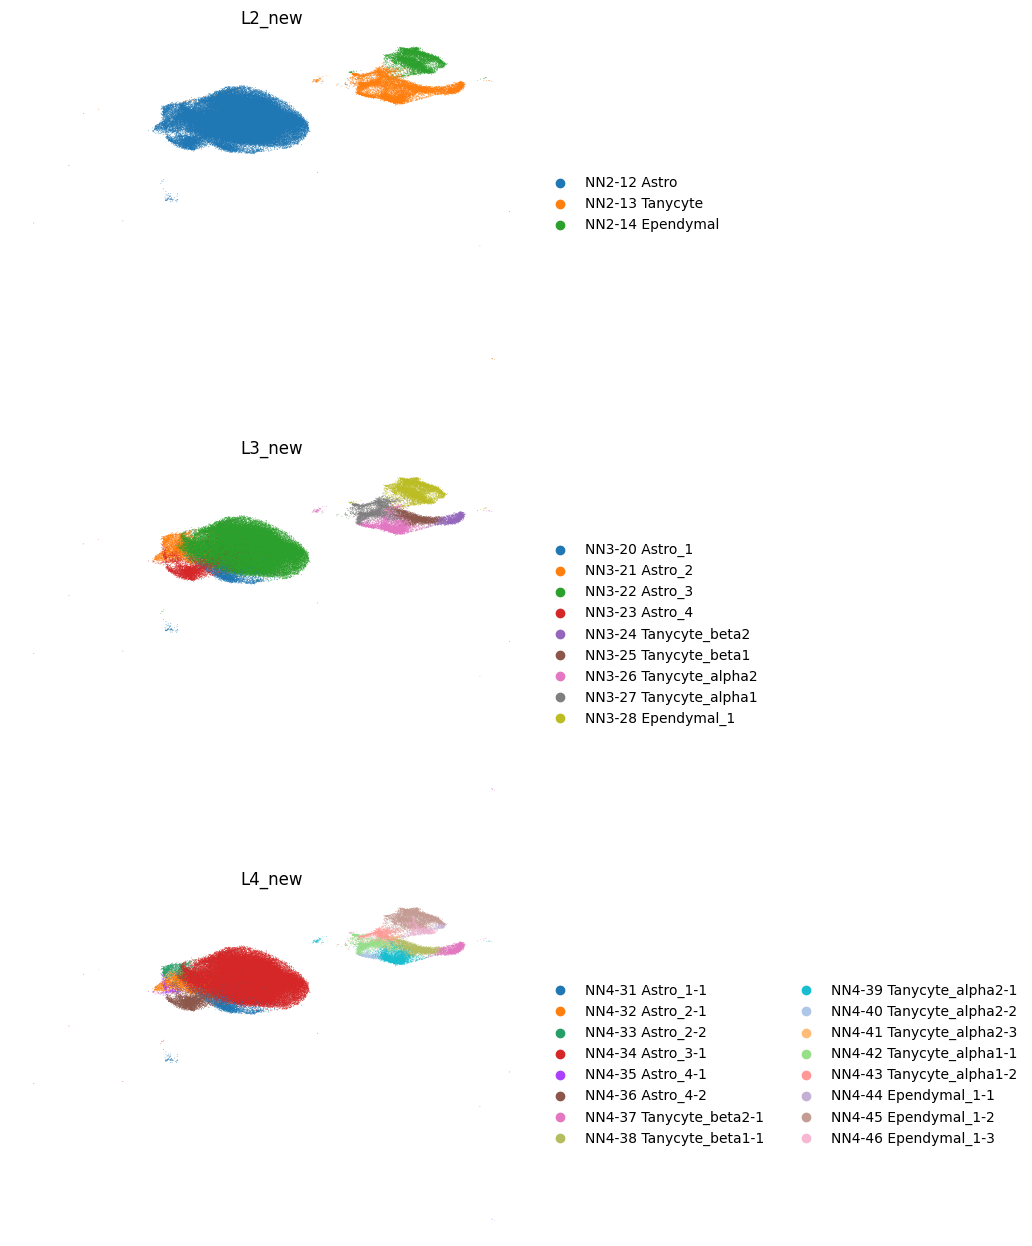

In [14]:
sc.pl.umap(ae_adata, color=["L2_new", "L3_new", "L4_new",], ncols=1, frameon=False)

## Let's annotate Oligos

In [15]:
oligo_adata = adata[adata.obs.L1.str.contains("Olig")].copy()

In [16]:
#sc.pl.umap(oligo_adata, color=["Pdgfra", "Mag", "L2"], ncols=2, frameon=False)

For the Oligo class, we have a split into oligodendrocyte precursor cells (OPCs) as well as Oligos with varying levels of maturation at L2.

In the ABC atlas, the Oligo subclass is further divided into four supertypes corresponding to different stages of oligodendrocyte maturation: committed oligodendrocyte precursors (COP), newly formed oligodendrocytes (NFOL), myelin-forming oligodendrocytes (MFOL), and mature oligodendrocytes (MOL).

For simplicity, Oligos are divided into Oligo_1 and Oligo_2 at L2.

In [17]:
oligo_manual = {
    # L2
    "NN2-1": "Oligo_1",
    "NN2-2": "Oligo_2",
    "NN2-3": "OPC",
 
}

In [18]:
annotate_NN_class_adata(
    adata = oligo_adata,
    manual_annot = oligo_manual,
)

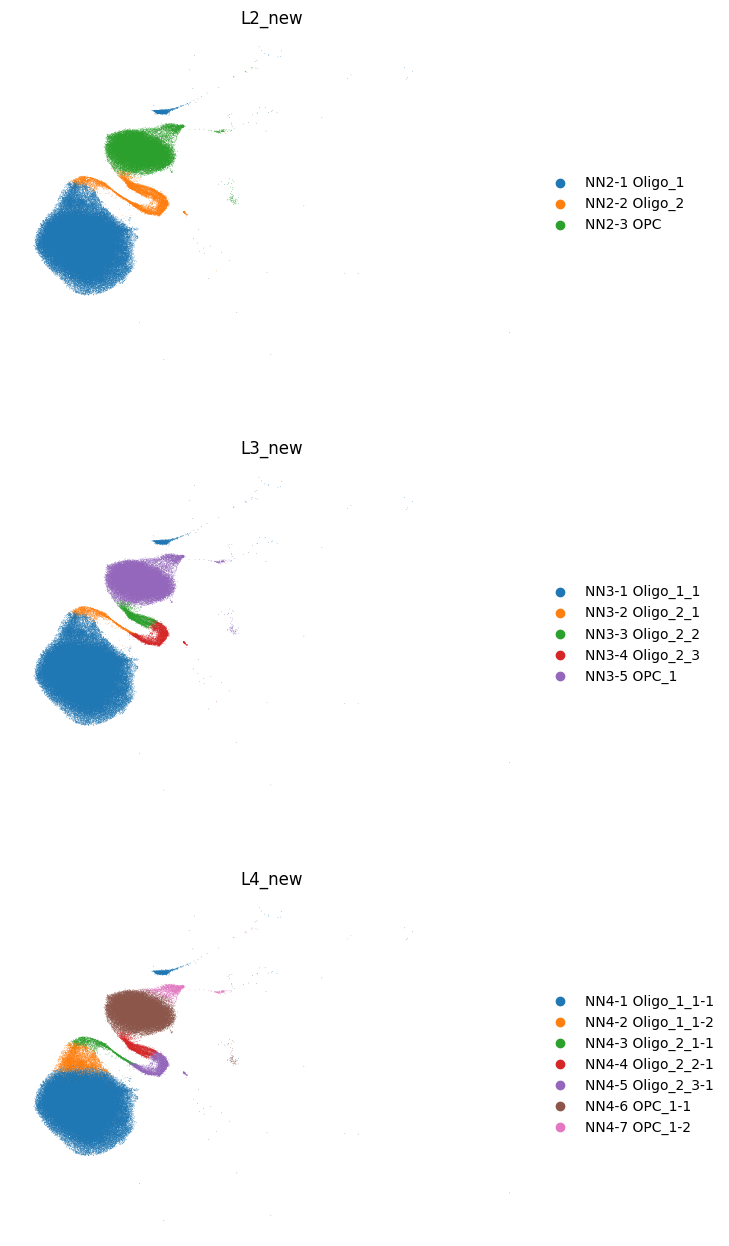

In [19]:
sc.pl.umap(oligo_adata, color=["L2_new", "L3_new", "L4_new",], ncols=1, frameon=False)

## Let's annotate vascular cells

On L2, vascular cells can be divided into VLMC, Endocytes, Pericytes as well as smooth muscle cells, similar to ABC.

In [20]:
vasc_adata = adata[adata.obs.L1.str.contains("Vasc")].copy()

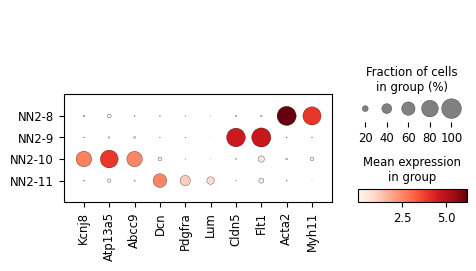

In [21]:
sc.pl.dotplot(vasc_adata, var_names=["Kcnj8", "Atp13a5", "Abcc9", # Peri
                            "Dcn", "Pdgfra", "Lum", # VLMC 
                            "Cldn5", "Flt1", # EC
                            "Acta2", "Myh11" # SMC
                            ], groupby="L2")

In [22]:
vasc_manual = {
    # L2
    "NN2-10": "Peri",
    "NN2-8": "SMC",
    "NN2-9": "Endo",
    "NN2-11": "VLMC",

}

In [23]:
annotate_NN_class_adata(
    adata = vasc_adata,
    manual_annot = vasc_manual,
)

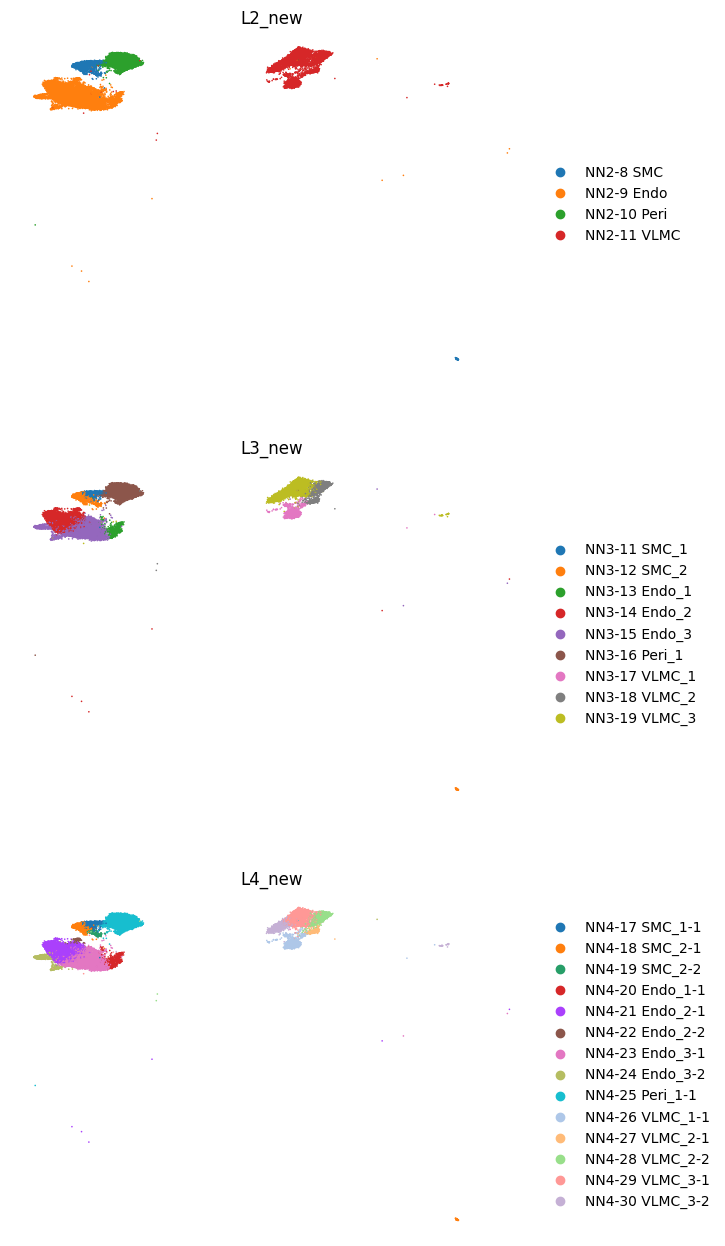

In [24]:
sc.pl.umap(vasc_adata, color=["L2_new", "L3_new", "L4_new",], ncols=1, frameon=False)

## Let's annotate immune cells

Immune cells split into homeostatic, nonhomeostatic migroglia as well as T cells and border-associated macrophages at L2.

In [25]:
immune_adata = adata[adata.obs.L1.str.contains("Immune")].copy()

In [26]:
#sc.pl.umap(immune_adata, color="L2", frameon=False)

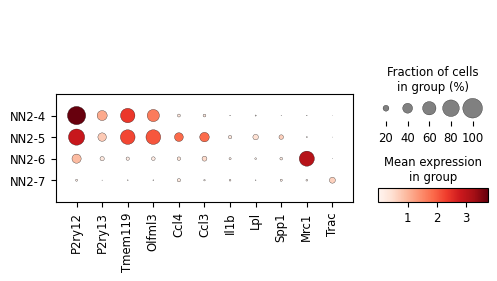

In [27]:
sc.pl.dotplot(immune_adata, var_names=["P2ry12", "P2ry13", "Tmem119", "Olfml3", # MG
                                        "Ccl4", "Ccl3", "Il1b", "Lpl", "Spp1",  # inflammation and disease markers for MGs
                                        "Mrc1", # BAMs #https://pmc.ncbi.nlm.nih.gov/articles/PMC10217436/
                                        "Trac" # T cells 
                                        ], groupby="L2")

In [28]:
immune_manual = {
    # L2
    "NN2-4": "Microglia_1",
    "NN2-5": "Microglia_2",
    "NN2-6": "BAM",
    "NN2-7": "T cell",

}

In [29]:
annotate_NN_class_adata(
    adata = immune_adata,
    manual_annot = immune_manual,
)

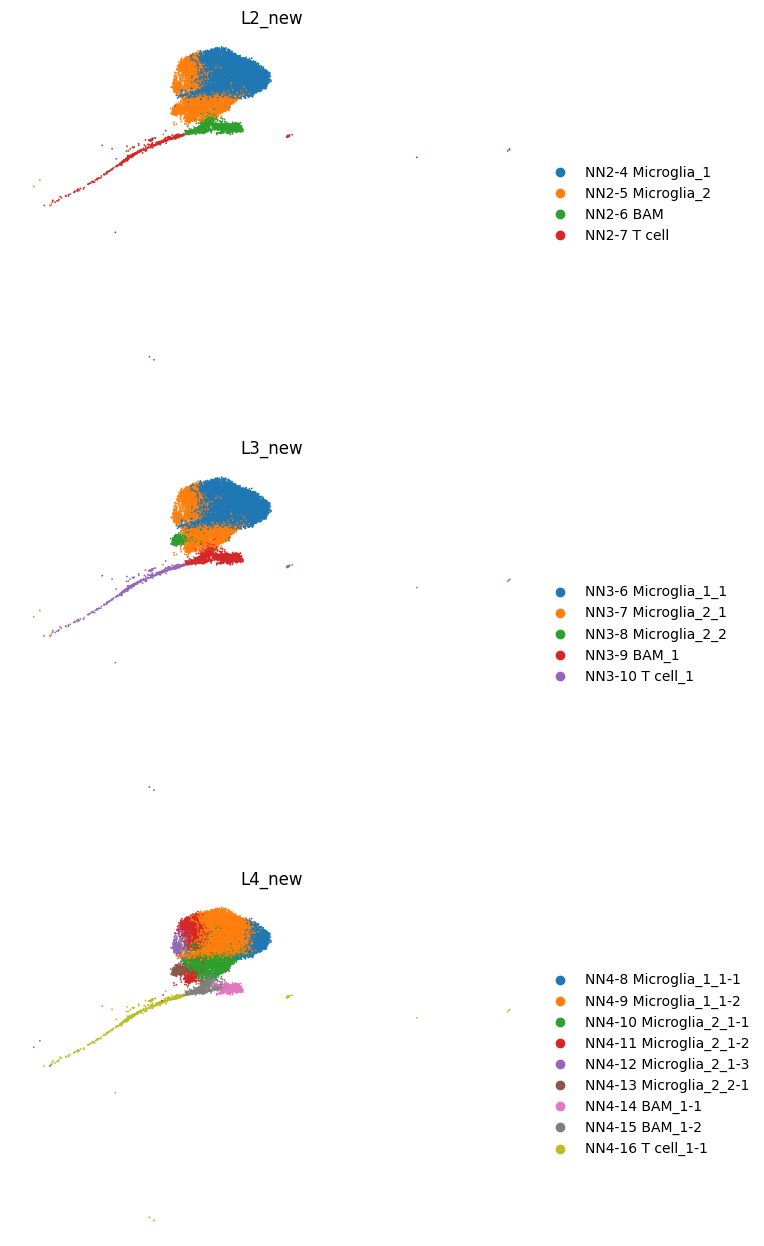

In [30]:
sc.pl.umap(immune_adata, color=["L2_new", "L3_new", "L4_new",], ncols=1, frameon=False)

## Combining

In [31]:
for i in range(2, 6):
    col = f"L{i}_new"
    
    # Initialize with "undefined"
    adata.obs[col] = "undefined"

    # Fill in annotations from subsets
    for an_subset in [ae_adata, immune_adata, oligo_adata, vasc_adata]:
        adata.obs.loc[an_subset.obs.index, col] = an_subset.obs[col].copy()


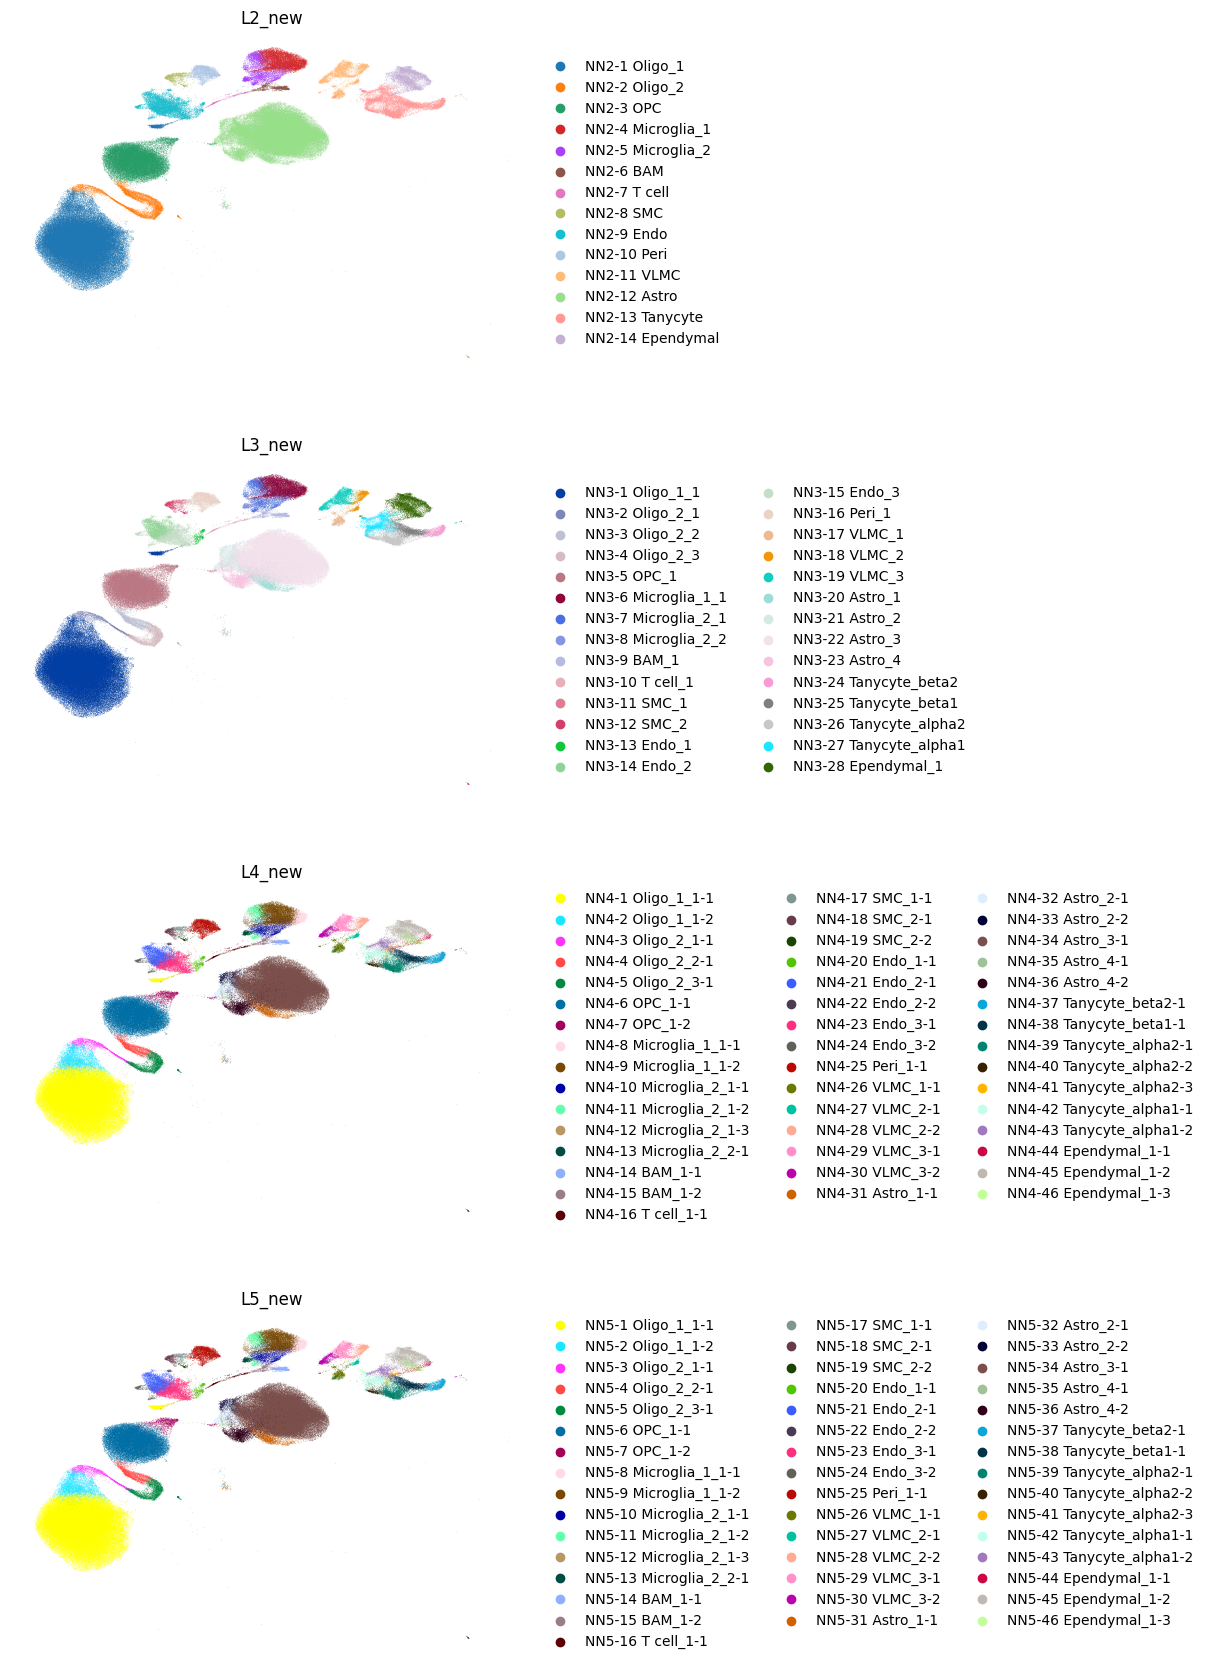

In [32]:
sc.pl.umap(adata, color = [f"L{i}_new" for i in range(2,6)], ncols = 1, frameon=False)

### Save annotation

In [35]:
nn_annot = adata.obs.loc[:, ["L1"] + [f"L{i}_new" for i in range(2,6)]].values.reshape(-1)
nn_annot = sorted(list(np.unique(nn_annot)))
nn_annot = pd.DataFrame({"annot": nn_annot})
nn_annot["ID"] = nn_annot.annot.apply(lambda x: x.split(" ")[0])
nn_annot = nn_annot.loc[:, ["ID", "annot"]]
nn_annot.loc[nn_annot.ID == "NN1-1", "annot"] = "NN1-1 OPC-Oligo"
nn_annot.head()

,ID,annot
0,NN1-1,NN1-1 OPC-Oligo
1,NN1-2,NN1-2 Immune
2,NN1-3,NN1-3 Vascular
3,NN1-4,NN1-4 Astro-Epen
4,NN2-1,NN2-1 Oligo_1


In [36]:
nn_annot.to_csv(OUTDIR / "NN_annot_mapper.csv", index=False)